<h2> Nauczanie maszynowe, Anna Garbarz, klasyfikacja
<h3>
W tym skrypcie zostały przeprowadzone kroki mające na celu wytrenowanie trzech różnych modeli do klasyfikacji komórek krwi. <br>

<h2> Opis wykonanych czynności: <br>
<h3> 0. Pobranie danych <br>
<h3> 1. Model 1 - na całych zdjęciach mikroskopowych: <br>
- Przygotowanie danych do treningu, walidacji i testu <br>
- Ujednolicenie rozmiarów, augumentacja <br>
- Sprawdzenie modelu na nieznormalizowanych danych <br>
- Znormalizowanie danych i wytrenowanie modelu <br>
<h3> 2. Model 2 - na celu do klasyfikacji: <br>
- Przygotowanie danych do wytrenowania modelu 2 - modelu do którego będą wchodzić jedynie zdjęcia z usuniętym tłem - gdzie będzie jedynie komórka wyodręniona jako cel do klasyfikacji <br>
- Przygotowanie takich danych - napisanie funkcji która wyodrębnia cel a tło pozostawia na szaro <br>
- Wytrenowanie modelu 2 <br>
<h3> 3. Model 3 - na celu do klasyfikacji + na cechach morfologicznych: <br>
- Obliczenie cech morfologicznych dla każdego zdjęcia <br>
- Połączenie cech morfologicznych i zdjęć w data loaderze <br>
- Wytrenowanie modelu <br>

In [ ]:
# Zaimportowanie bibliotek
import kagglehub
import tensorflow as tf
from sklearn.model_selection import train_test_split
import os
import shutil
from PIL import Image
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import torch
import torchvision

from torchvision.datasets import ImageFolder
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


<h2> 0. Przygotowanie danych: <br>
a) Pobranie

In [ ]:
# Pobranie danych
path = kagglehub.dataset_download("mahdihabibi/segmented-peripheral-blood-cells-using-opencv")
print(path)

100%|██████████| 29.8M/29.8M [00:00<00:00, 190MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1


Dane podzielone są na dwa foldery - maski oraz zdjęcia gdzie w każdym folderze zdjęcia są podzielone na foldery odopwiadające nazwom komórek:

In [ ]:
!ls /root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1

binary_masks  original_images


In [ ]:
!ls /root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/original_images/original_images

basophil  eosinophil  erythroblast  ig	lymphocyte  monocyte  neutrophil  platelet


In [ ]:
data_dir = "/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/original_images/original_images/"

# Lista klas
classes = os.listdir(data_dir)
print("Lista klas:", classes)


Lista klas: ['lymphocyte', 'eosinophil', 'erythroblast', 'neutrophil', 'basophil', 'ig', 'platelet', 'monocyte']


---

<h2> 1. Model 1: <br>
- Podział danych na trenongowy, walidacyjny oraz testowy

In [ ]:
base_dir = "./prepared_data/" # tutaj będą zapisywane podzielone zdjęcia
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")
test_dir = os.path.join(base_dir, "test")

for split in [train_dir, val_dir, test_dir]:
    for cls in classes:
        os.makedirs(os.path.join(split, cls), exist_ok=True)

# Funkcja do podziału danych
def split_data(source_dir, train_dir, val_dir, test_dir, split_ratio=(0.7, 0.15, 0.15)):
    for cls in classes:
        images = os.listdir(os.path.join(source_dir, cls))
        train, temp = train_test_split(images, test_size=(1 - split_ratio[0]))
        val, test = train_test_split(temp, test_size=(split_ratio[2] / (split_ratio[1] + split_ratio[2])))

        for img in train:
            shutil.copy(os.path.join(source_dir, cls, img), os.path.join(train_dir, cls, img))
        for img in val:
            shutil.copy(os.path.join(source_dir, cls, img), os.path.join(val_dir, cls, img))
        for img in test:
            shutil.copy(os.path.join(source_dir, cls, img), os.path.join(test_dir, cls, img))

split_data(data_dir, train_dir, val_dir, test_dir)


Sprawdzenie czy obrazy mają takie same rozmiary:

In [ ]:
data_dir = "/root/.cache/kagglehub/datasets/mahdihabibi/segmented-peripheral-blood-cells-using-opencv/versions/1/original_images/original_images/"

# Funkcja do sprawdzania rozmiarów obrazów
def check_unique_image_sizes(data_dir):
    sizes = []
    for class_name in os.listdir(data_dir):
        class_path = os.path.join(data_dir, class_name)
        if os.path.isdir(class_path):
            for img_name in os.listdir(class_path):
                img_path = os.path.join(class_path, img_name)
                try:
                    with Image.open(img_path) as img:
                        width, height = img.size
                        sizes.append((width, height))
                except Exception as e:
                    print(f"Nie udało się otworzyć obrazu: {img_path}, błąd: {e}")
    return Counter(sizes)

image_size_counts = check_unique_image_sizes(data_dir)

# Wyświetlenie unikalnych rozmiarów i liczby obrazów
for size, count in image_size_counts.items():
    print(f"Rozdzielczość: {size}, Liczba obrazów: {count}")


Rozdzielczość: (360, 363), Liczba obrazów: 1514
Rozdzielczość: (366, 369), Liczba obrazów: 30
Rozdzielczość: (360, 360), Liczba obrazów: 16


Obrazy nie mają takich samych rozmiarów, zatem konieczne było ujednolicenie rozmiaru do 360,363

<h2> Ujednolicenie rozmiarów obrazów:

In [ ]:
# Funkcja do interpolacji obrazu
def resize_image(image_path, new_width, new_height, filter_size=(3, 3), padding=0, stride=1):
    img = Image.open(image_path)
    img_array = np.array(img)
    H, W = img_array.shape
    padded_image = np.pad(img_array, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)

    output_height = (H - filter_size[0] + 2 * padding) // stride + 1
    output_width = (W - filter_size[1] + 2 * padding) // stride + 1

    resized_image = np.zeros((new_height, new_width))
    for i in range(new_height):
        for j in range(new_width):
            x_start = int(j * (W / new_width))
            y_start = int(i * (H / new_height))
            x_end = x_start + filter_size[1]
            y_end = y_start + filter_size[0]

            region = padded_image[y_start:y_end, x_start:x_end]
            resized_image[i, j] = np.mean(region)

    return resized_image

In [ ]:
def resize_image_pillow(image_path, new_width, new_height, save_path):
    img = Image.open(image_path)
    resized_img = img.resize((new_width, new_height), Image.LANCZOS)
    resized_img.save(save_path)

Zapis do nowego folderu:

In [ ]:
base_dir = "./prepared_data/"
output_dir = "./resized_data/"
os.makedirs(output_dir, exist_ok=True)

splits = ['train', 'val', 'test']

new_width = 360
new_height = 363

for split in splits:
    input_dir = os.path.join(base_dir, split)
    output_split_dir = os.path.join(output_dir, split)
    os.makedirs(output_split_dir, exist_ok=True)

    for class_name in os.listdir(input_dir):
        class_input_dir = os.path.join(input_dir, class_name)
        class_output_dir = os.path.join(output_split_dir, class_name)
        os.makedirs(class_output_dir, exist_ok=True)

        for img_name in os.listdir(class_input_dir):
            img_path = os.path.join(class_input_dir, img_name)
            output_path = os.path.join(class_output_dir, img_name)

            try:
                resize_image_pillow(img_path, new_width, new_height, output_path)
            except Exception as e:
                print(f"Błąd podczas przetwarzania {img_path}: {e}")

print("Wszystkie obrazy zostały przetworzone.")


Wszystkie obrazy zostały przetworzone.


Data loader dla danych treningowych: <br>


Początkowo myślałam, że w naszym przypadku kolory mają znaczenie - więc zdecydowałam się nie wykonywać w transformacji normalizacji. Okazało się później, że moje myślenie było błędne, bo zdjęcia po normalizacji trenowały się o niebo lepiej! <br>

Miałyśmy też dosyć mało danych - zdecydowałyśmy się wykonać augumentację:
- losowy obrót poziomy,
- odbicie w pionie
- obrót obrazu o losowy kąt

In [ ]:
# bez normalizacji
base_dir = "./resized_data/train"
batch_size = 64

transform = transforms.Compose([
    # Augmentacja
    transforms.RandomHorizontalFlip(),  # Losowy poziomy obrót
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomVerticalFlip(p=0.5), # losowe odbicie w pionie

    transforms.ToTensor(),
])

dataset = ImageFolder(root=base_dir, transform=transform)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

Sprawdzenie liczebności klas:

In [ ]:
from collections import Counter

class_counts = Counter()
for images, labels in train_loader:
    class_counts.update(labels.tolist())

for class_id, count in class_counts.items():
    print(f"Klasa {class_id}: {count} próbek")


Klasa 3: 136 próbek
Klasa 6: 136 próbek
Klasa 0: 136 próbek
Klasa 5: 136 próbek
Klasa 7: 136 próbek
Klasa 4: 136 próbek
Klasa 1: 136 próbek
Klasa 2: 136 próbek


Tutaj widać że augumentacja nie zwiększyła liczebności klas a jest to spowodowane tym, że augumentacja działa "na bieżąco" gdy dane są ładowane do modelu, więc tutaj nie zobaczymy zwiększonej liczby klas.

In [ ]:
# BEZ NORMALIZACJI:

In [ ]:
base_dir = "./resized_data/train"
batch_size = 32

transform = transforms.Compose([
    # Augmentacja
    transforms.RandomHorizontalFlip(),  # Losowy poziomy obrót
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.ToTensor(),  # Konwersja do tensora


])

dataset = ImageFolder(root=base_dir, transform=transform)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

Sprawdzenie jak wyglądają przykładowe zdjęcia:

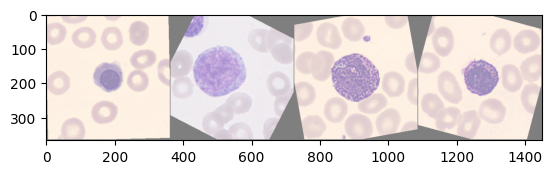

Etykiety: [2 3 0 0]


In [ ]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

dataiter = iter(train_loader)
images, labels = next(dataiter)


imshow(torchvision.utils.make_grid(images[:4]))  # Wyświetlanie pierwszych 4 obrazów w partii

print('Etykiety:', labels[:4].numpy())


Trening pierwszego modelu opartego jedynie o zdjęcia. Początkowo wykonywałam trening w oparciu o dane bez normalizacji.

Struktura pierwszego modelu: <br>
Model ConvNet jest siecią konwolucyjną składającą się z trzech warstw konwolucyjnych.

- Warstwa konwolucyjna (nn.Conv2d) z filtrem 3x3, krokiem 1 i paddingiem 1.
- Batch Normalization (nn.BatchNorm2d), która stabilizuje uczenie.
- Funkcję aktywacji ReLU.
- Max pooling (nn.MaxPool2d) o rozmiarze 2x2 i kroku 2, co zmniejsza rozmiar map cech o połowę.


In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc1 = nn.Linear(128 * 45 * 45, 512)
        self.fc2 = nn.Linear(512, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)

        # Spłaszczenie obrazu po warstwach konwolucyjnych
        out = out.view(out.size(0), -1)

        # Warstwy pełne (FC) z funkcją aktywacji
        out = self.dropout(self.fc1(out))  # Dropout i ReLU
        out = nn.ReLU()(self.fc2(out))    # Dodanie aktywacji ReLU
        out = self.fc3(out)               # Wyjście, bez aktywacji (użyj softmax przy obliczaniu strat)

        return out


In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = ConvNet(num_classes).to(device)

In [ ]:
device

device(type='cuda', index=0)

In [ ]:
#Parametry do trenowania
num_epochs = 10
learning_rate = 0.001

In [ ]:
#Wybieramy funckje kosztu i optymalizator
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
total_step = len(train_loader)

In [ ]:
# Trening modelu
all_losses = []
for epoch in range(num_epochs):
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if (i+1) % 20 == 0:
            print ('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                   .format(epoch+1, num_epochs, i+1, total_step, loss.item()))
        all_losses.append(loss.item())

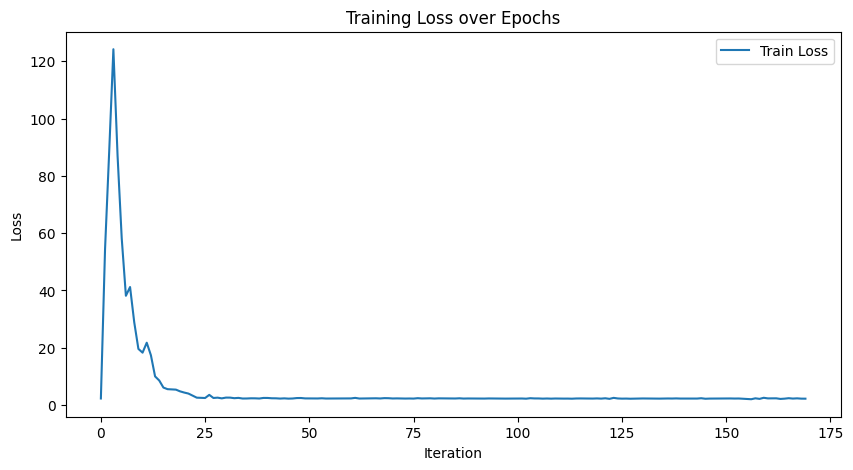

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(all_losses, label='Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.show()

Przy pierwszym treningu niestety nie wyświetlała mi się wartość funkcji kosztu, jednak po wyświetleniu jej w formie wykresu, widzimy że funkcja bardzo szybko spada, co może budzić pewne wątpliwości. <br>

Sprawdzenie dokładności na danych testowych:

In [ ]:
base_dir = "./resized_data/test"
batch_size = 32
transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
])

dataset = ImageFolder(root=base_dir, transform=transform)
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [ ]:
with torch.no_grad():
    correct = 0 #liczba poprawnie sklasyfikowanych
    total = 0  #liczba wszystkich
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f'Test Accuracy: {100 * correct / total}')

Test Accuracy: 75.73033707865169


Dalej nie było zbyt idealnie, chciałam sprawdzić czy może trudniejszy model coś naprawi:

In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )


        self.fc1 = nn.Linear(128 * 45 * 45, 512)
        self.fc2 = nn.Linear(512, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)

        out = out.view(out.size(0), -1)
        out = self.dropout(self.fc1(out))  # Dropout i ReLU
        out = nn.ReLU()(self.fc2(out))    # Dodanie aktywacji ReLU
        out = self.fc3(out)               # Wyjście, bez aktywacji (użyj softmax przy obliczaniu strat)

        return out

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')  # Użyj GPU, jeśli dostępny
num_classes = 10
model = ConvNet(num_classes).to(device)

# Parametry do trenowania
num_epochs = 15
learning_rate = 0.001

# Wybieramy funkcję kosztu i optymalizator
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

total_step = len(train_loader)

# Trening modelu
all_losses = []
for epoch in range(num_epochs):
    running_loss = 0.0
    correct = 0
    total = 0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        # Monitorowanie dokładności
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        if (i+1) % 20 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}')

        all_losses.append(loss.item())

    # Aktualizacja learning rate
    scheduler.step()

    # Obliczanie dokładności
    accuracy = 100 * correct / total
    print(f'Epoch [{epoch+1}/{num_epochs}], Accuracy: {accuracy:.2f}%')

# Zapis modelu po treningu
torch.save(model.state_dict(), 'model.pth')
print('Model saved successfully.')


Epoch [1/15], Step [20/34], Loss: 8.2227
Epoch [1/15], Accuracy: 13.05%
Epoch [2/15], Step [20/34], Loss: 2.4297
Epoch [2/15], Accuracy: 13.88%
Epoch [3/15], Step [20/34], Loss: 2.0761
Epoch [3/15], Accuracy: 12.22%
Epoch [4/15], Step [20/34], Loss: 2.2945
Epoch [4/15], Accuracy: 12.50%
Epoch [5/15], Step [20/34], Loss: 2.0821
Epoch [5/15], Accuracy: 12.22%
Epoch [6/15], Step [20/34], Loss: 2.0347
Epoch [6/15], Accuracy: 12.13%
Epoch [7/15], Step [20/34], Loss: 2.0067
Epoch [7/15], Accuracy: 11.58%
Epoch [8/15], Step [20/34], Loss: 1.9732
Epoch [8/15], Accuracy: 20.31%
Epoch [9/15], Step [20/34], Loss: 2.0756
Epoch [9/15], Accuracy: 21.51%
Epoch [10/15], Step [20/34], Loss: 2.0362
Epoch [10/15], Accuracy: 24.08%
Epoch [11/15], Step [20/34], Loss: 1.8873
Epoch [11/15], Accuracy: 23.25%
Epoch [12/15], Step [20/34], Loss: 1.9505
Epoch [12/15], Accuracy: 23.99%
Epoch [13/15], Step [20/34], Loss: 1.9285
Epoch [13/15], Accuracy: 22.79%
Epoch [14/15], Step [20/34], Loss: 1.7909
Epoch [14/15],

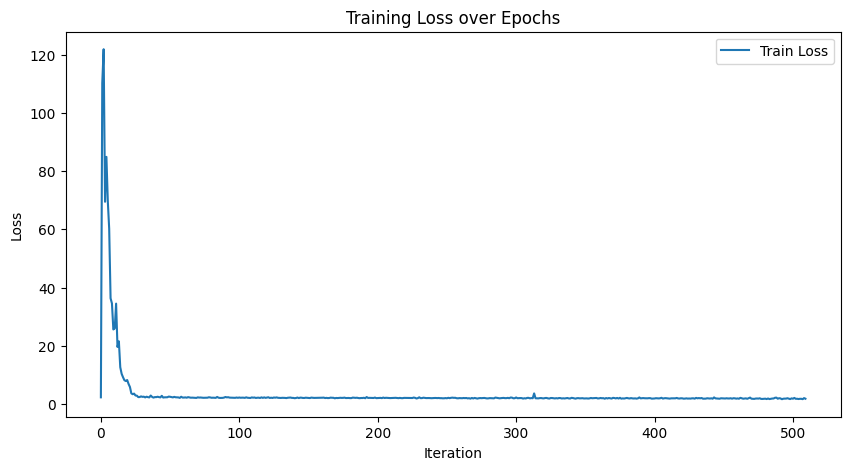

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(all_losses, label='Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.show()

In [ ]:
with torch.no_grad():
    correct = 0 #liczba poprawnie sklasyfikowanych
    total = 0  #liczba wszystkich
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f'Test Accuracy: {100 * correct / total}')

Test Accuracy: 25.416666666666668


Jak widać skomplikowanie modelu jeszcze bardziej pogorszyło całą sytuację :(

TRENING MODELU W OPARCIU O ZNORMALIZOWANE DANE + ZWIĘKSZONA AUGUMENTACJA:

In [ ]:
base_dir = "./resized_data/train"
batch_size = 64

transform = transforms.Compose([
    # Augmentacja
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomHorizontalFlip(),  # Losowe odbicie w poziomie
    transforms.RandomVerticalFlip(),   # Losowe odbicie w pionie
    transforms.RandomAffine(30, shear=10, scale=(0.8, 1.2)),  # Losowe przesunięcie, obrót, skalowanie
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])

dataset = ImageFolder(root=base_dir, transform=transform)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


base_dir = "./resized_data/test"

transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])


dataset = ImageFolder(root=base_dir, transform=transform)
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

Sprawdzenie jak wyglądają przykładowe zdjęcia - już po normalizacji - po jednym dla każdej klasy:

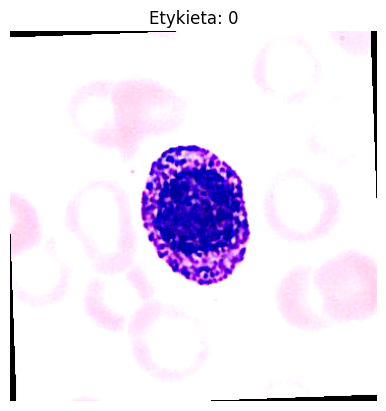

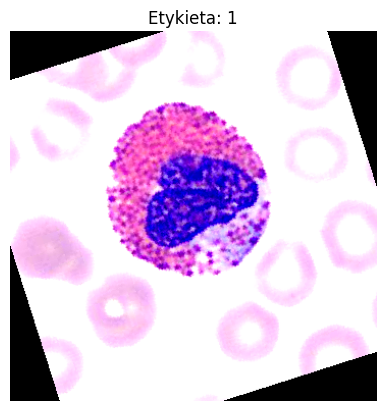

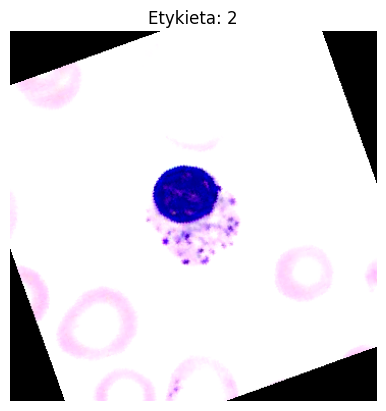

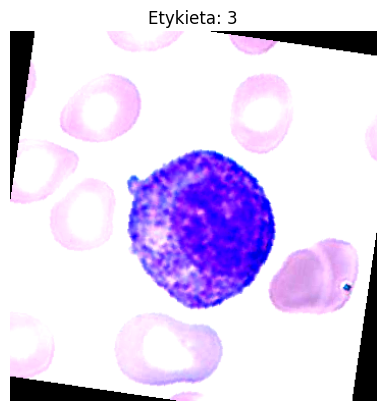

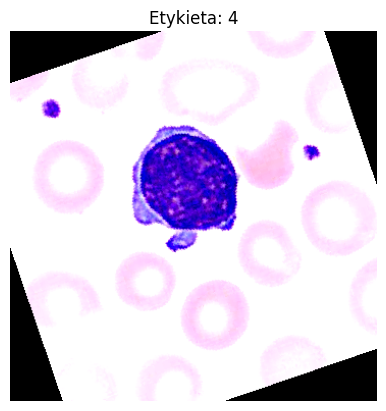

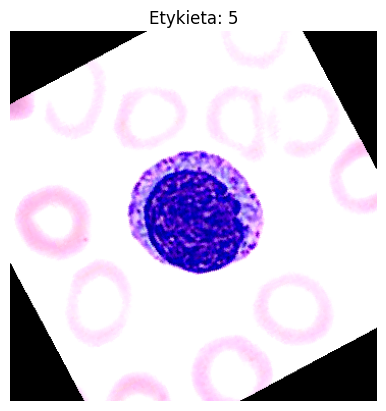

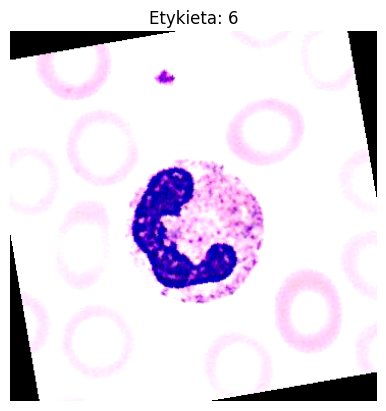

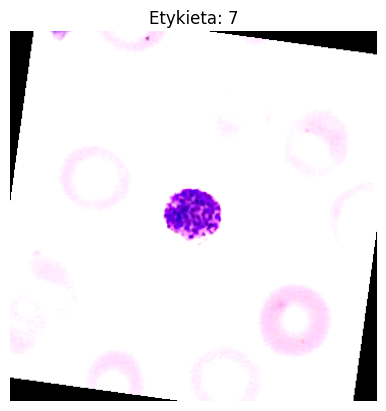

In [ ]:
def imshow(img, label=None):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if label is not None:
        plt.title(f"Etykieta: {label}")
    plt.axis("off")
    plt.show()

unique_images = {}
for images, labels in train_loader:
    for img, label in zip(images, labels):
        if label.item() not in unique_images:
            unique_images[label.item()] = img
        if len(unique_images) == len(dataset.classes):
            break
    if len(unique_images) == len(dataset.classes):
        break

for label, img in sorted(unique_images.items()):
    imshow(img, label=label)


Funkcja do treningu modelu i sprawdzenia na zbiorze walidacyjnym z różnymi hiperparametrami:

In [ ]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score

# Przykładowa funkcja trenująca model z różnymi hiperparametrami
def train_model(model, train_loader, val_loader, epochs=15, lr=0.001, batch_size=32):
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    # Optymalizator i funkcja kosztu
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Trening
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader)}")

    # Walidacja
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())

    # Zlicz dokładność
    all_preds = torch.cat(all_preds)
    all_labels = torch.cat(all_labels)
    accuracy = accuracy_score(all_labels, all_preds)

    return accuracy


In [ ]:
# Przykład przestrzeni hiperparametrów
param_grid = {
    'lr': [0.001, 0.01, 0.005],  # Learning rate
    'epochs': [5, 10, 15],    # Liczba epok
    'batch_size': [32, 64, 128] # Rozmiar partii
}


In [ ]:
base_dir = "./resized_data/val"
batch_size = 32
transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
])

dataset = ImageFolder(root=base_dir, transform=transform)
val_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [ ]:
results = []

for params in ParameterGrid(param_grid):
    print(f"Training with parameters: {params}")

    model = ConvNet(num_classes=10)
    accuracy = train_model(model, train_loader, val_loader, **params)

    results.append({**params, 'accuracy': accuracy})
best_params = max(results, key=lambda x: x['accuracy'])
print(f"Best parameters: {best_params}")


Training with parameters: {'batch_size': 32, 'epochs': 5, 'lr': 0.001}
Epoch [1/5], Loss: 22.70110583305359
Epoch [2/5], Loss: 2.406982513035045
Epoch [3/5], Loss: 2.315794446889092
Epoch [4/5], Loss: 2.3275153636932373
Epoch [5/5], Loss: 2.293991916319903
Training with parameters: {'batch_size': 32, 'epochs': 5, 'lr': 0.01}
Epoch [1/5], Loss: 677.4061151322196
Epoch [2/5], Loss: 2.377008985070621
Epoch [3/5], Loss: 2.1910564198213467
Epoch [4/5], Loss: 2.180618868154638
Epoch [5/5], Loss: 2.4521244483835556
Training with parameters: {'batch_size': 32, 'epochs': 5, 'lr': 0.005}
Epoch [1/5], Loss: 180.16360123017256
Epoch [2/5], Loss: 2.2588351193596337
Epoch [3/5], Loss: 2.2355704728294823
Epoch [4/5], Loss: 2.201759128009572
Epoch [5/5], Loss: 2.1951557678334854
Training with parameters: {'batch_size': 32, 'epochs': 10, 'lr': 0.001}
Epoch [1/10], Loss: 26.70767862656537
Epoch [2/10], Loss: 2.426156387609594
Epoch [3/10], Loss: 2.3181670974282658
Epoch [4/10], Loss: 2.324321887072395
E

In [ ]:
# Best parameters: {'batch_size': 64, 'epochs': 10, 'lr': 0.001, 'accuracy': 0.31896551724137934}

Tutaj sprawdzałam wieeele architektur modelu i testowałam różne hiperparametry ale dla Pana zostawiłam jedynie część z moich prób :D

We wszystkich modelach zrezygnowałam z SoftMax ponieważ używałam CrossEntropyLoss.

In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),  # Filtry
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)  # MaxPooling
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),  # Filtry
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)  # MaxPooling
        )

        self.fc1 = nn.Linear(64 * 90 * 90, 128)
        self.fc2 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        # Przechodzimy przez warstwy konwolucyjne
        out = self.layer1(x)
        out = self.layer2(out)

        out = out.view(out.size(0), -1)  # Rozmiar [batch_size, 64*90*90]

        # Warstwy pełne (FC)
        out = self.dropout(self.fc1(out))  # Dropout i aktywacja
        out = self.fc2(out)
        return out


In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = ConvNet(num_classes).to(device)

In [ ]:
total_step = len(train_loader)
num_epochs = 10
learning_rate = 0.0001

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
# Trening modelu
all_losses = []
for epoch in range(num_epochs):
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if (i+1) % 1 == 0:
            print ('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                   .format(epoch+1, num_epochs, i+1, total_step, loss.item()))
        all_losses.append(loss.item())

Epoch [1/10], Step [1/23], Loss: 2.4164
Epoch [1/10], Step [2/23], Loss: 409.4744
Epoch [1/10], Step [3/23], Loss: 331.4403
Epoch [1/10], Step [4/23], Loss: 292.6383
Epoch [1/10], Step [5/23], Loss: 355.2008
Epoch [1/10], Step [6/23], Loss: 297.4212
Epoch [1/10], Step [7/23], Loss: 294.3514
Epoch [1/10], Step [8/23], Loss: 262.1397
Epoch [1/10], Step [9/23], Loss: 218.3519
Epoch [1/10], Step [10/23], Loss: 279.4318
Epoch [1/10], Step [11/23], Loss: 162.4101
Epoch [1/10], Step [12/23], Loss: 162.8065
Epoch [1/10], Step [13/23], Loss: 101.9957
Epoch [1/10], Step [14/23], Loss: 60.9082
Epoch [1/10], Step [15/23], Loss: 96.5878
Epoch [1/10], Step [16/23], Loss: 115.6749
Epoch [1/10], Step [17/23], Loss: 131.6368
Epoch [1/10], Step [18/23], Loss: 85.3803
Epoch [1/10], Step [19/23], Loss: 70.7514
Epoch [1/10], Step [20/23], Loss: 62.7457
Epoch [1/10], Step [21/23], Loss: 91.6015
Epoch [1/10], Step [22/23], Loss: 80.8573
Epoch [1/10], Step [23/23], Loss: 76.2332
Epoch [2/10], Step [1/23], Los

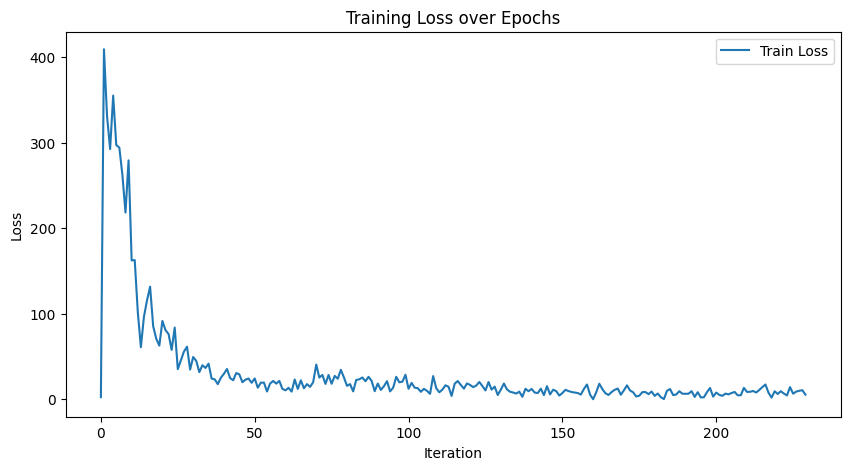

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(all_losses, label='Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.show()

Sprawdzenie dokładności na zbiorze testowym:

In [ ]:
with torch.no_grad():
    correct = 0 #liczba poprawnie sklasyfikowanych
    total = 0  #liczba wszystkich
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f'Test Accuracy: {100 * correct / total}')

Test Accuracy: 76.85393258426966


Poniżej pokazuję jeszcze jak wyglądała funkcja kosztu gdy nie uwzględniłam regularyzacji L1, widać że funkcja kosztu bardzo się wahała - a model się nie uczył.

Epoch [1/10], Step [20/45], Loss: 42.6075
Epoch [1/10], Step [40/45], Loss: 22.6323
Epoch [1/10] Training Accuracy: 0.4016, F1 Score: 0.3435
Epoch [1/10] Test Accuracy: 0.1258, F1 Score: 0.0291
Epoch [2/10], Step [20/45], Loss: 13.6419
Epoch [2/10], Step [40/45], Loss: 8.3600
Epoch [2/10] Training Accuracy: 0.5363, F1 Score: 0.5274
Epoch [2/10] Test Accuracy: 0.1933, F1 Score: 0.1212
Epoch [3/10], Step [20/45], Loss: 7.9575
Epoch [3/10], Step [40/45], Loss: 9.4257
Epoch [3/10] Training Accuracy: 0.6683, F1 Score: 0.6398
Epoch [3/10] Test Accuracy: 0.1281, F1 Score: 0.0291
Epoch [4/10], Step [20/45], Loss: 6.8500
Epoch [4/10], Step [40/45], Loss: 4.1475
Epoch [4/10] Training Accuracy: 0.7424, F1 Score: 0.7389
Epoch [4/10] Test Accuracy: 0.1281, F1 Score: 0.0291
Epoch [5/10], Step [20/45], Loss: 2.9092
Epoch [5/10], Step [40/45], Loss: 3.0327
Epoch [5/10] Training Accuracy: 0.7114, F1 Score: 0.6742
Epoch [5/10] Test Accuracy: 0.2427, F1 Score: 0.1748
Epoch [6/10], Step [20/45], Loss: 6.0

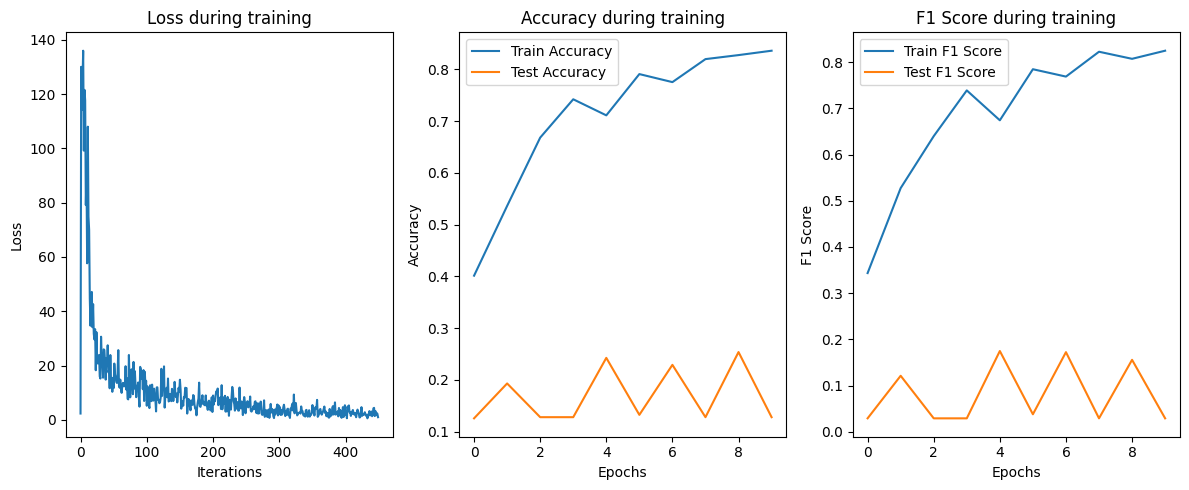

In [ ]:
all_losses = []
train_accuracies = []
test_accuracies = []
train_f1_scores = []
test_f1_scores = []

# Funkcja do obliczania metryk na zbiorze
def compute_metrics(model, data_loader, device):
    model.eval()  # Ustawienie modelu w tryb ewaluacji
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return accuracy, f1

# Trening modelu
for epoch in range(num_epochs):
    model.train()  # Ustawienie modelu w tryb treningowy
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        if (i + 1) % 20 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}')

        all_losses.append(loss.item())

    # Obliczanie metryk na treningowym zbiorze
    train_accuracy, train_f1 = compute_metrics(model, train_loader, device)
    train_accuracies.append(train_accuracy)
    train_f1_scores.append(train_f1)

    # Obliczanie metryk na testowym zbiorze
    test_accuracy, test_f1 = compute_metrics(model, test_loader, device)
    test_accuracies.append(test_accuracy)
    test_f1_scores.append(test_f1)

    print(f'Epoch [{epoch+1}/{num_epochs}] Training Accuracy: {train_accuracy:.4f}, F1 Score: {train_f1:.4f}')
    print(f'Epoch [{epoch+1}/{num_epochs}] Test Accuracy: {test_accuracy:.4f}, F1 Score: {test_f1:.4f}')

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(all_losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Loss during training')

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy during training')
plt.legend()

# F1 Score
plt.subplot(1, 3, 3)
plt.plot(train_f1_scores, label='Train F1 Score')
plt.plot(test_f1_scores, label='Test F1 Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('F1 Score during training')
plt.legend()


plt.tight_layout()
plt.show()


Tutaj poniżej już zostawiam model który okazał się dawać najlepsze wyniki spośród wszystkich. Dodanie regularyzacji L1 oraz L2 spowodowało, że funkcja kosztu była bardziej ustabilizowana, ponieważ przed dodaniem tego, funkcja raz rosła, raz malała.

Poniższy model okazał się dawać najlepsze wyniki z poprzednich - zmniejszyłam liczbę filtrów ale zostawiłam 3 warstwę konwolucyjną.

In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.fc1 = nn.Linear(128 * 45 * 45, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)

        out = out.view(out.size(0), -1)

        out = self.dropout(out)
        out = self.fc1(out)
        out = nn.ReLU()(out)
        out = self.fc2(out)

        return out

Opis architektury tego modelu:

Konwolucyjna sieć neuronowa. Składa się z trzech bloków konwolucyjnych, z których każdy zawiera warstwę konwolucyjną (3x3), batch normalizację, funkcję aktywacji ReLU oraz max pooling. Po przetworzeniu przez warstwy konwolucyjne dane są spłaszczane, a następnie przechodzą przez dwie w pełni połączone warstwy, które mapują cechy na klasy wyjściowe. Dropout (0.3) jest stosowany, aby zapobiec przeuczeniu modelu.

Ostateczne parametry jakie okazały się być najlepsze do wytrenowania tego modelu:
- batch size: 64
- learing rate: 0.0001
- L1 lambda: 0.001

In [ ]:
base_dir = "./resized_data/train"
batch_size = 64

transform = transforms.Compose([
    # Augmentacja
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomHorizontalFlip(),  # Losowe odbicie w poziomie
    transforms.RandomVerticalFlip(),   # Losowe odbicie w pionie
    transforms.RandomAffine(30, shear=10, scale=(0.8, 1.2)),  # Losowe przesunięcie, obrót, skalowanie
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])

dataset = ImageFolder(root=base_dir, transform=transform)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


base_dir = "./resized_data/test"

transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])


dataset = ImageFolder(root=base_dir, transform=transform)
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [ ]:
total_step = len(train_loader)
#Parametry do trenowania
num_epochs = 15
learning_rate = 0.0001
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = ConvNet(num_classes).to(device)
#Wybieramy funckje kosztu i optymalizator - dodanie L2 - WEIGHT DECAY
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)

Epoch [1/15], Step [2/17], Loss: 80.1667
Epoch [1/15], Step [4/17], Loss: 69.4561
Epoch [1/15], Step [6/17], Loss: 61.8696
Epoch [1/15], Step [8/17], Loss: 56.7983
Epoch [1/15], Step [10/17], Loss: 53.5663
Epoch [1/15], Step [12/17], Loss: 47.4698
Epoch [1/15], Step [14/17], Loss: 42.6832
Epoch [1/15], Step [16/17], Loss: 39.4008
Epoch [1/15] Training Accuracy: 0.1590, F1 Score: 0.0716
Epoch [1/15] Test Accuracy: 0.1417, F1 Score: 0.0529
Epoch [2/15], Step [2/17], Loss: 35.2517
Epoch [2/15], Step [4/17], Loss: 33.4770
Epoch [2/15], Step [6/17], Loss: 31.1408
Epoch [2/15], Step [8/17], Loss: 29.4356
Epoch [2/15], Step [10/17], Loss: 27.9131
Epoch [2/15], Step [12/17], Loss: 26.0616
Epoch [2/15], Step [14/17], Loss: 24.4904
Epoch [2/15], Step [16/17], Loss: 23.1259
Epoch [2/15] Training Accuracy: 0.3732, F1 Score: 0.3136
Epoch [2/15] Test Accuracy: 0.3375, F1 Score: 0.2512
Epoch [3/15], Step [2/17], Loss: 21.0585
Epoch [3/15], Step [4/17], Loss: 20.0050
Epoch [3/15], Step [6/17], Loss: 1

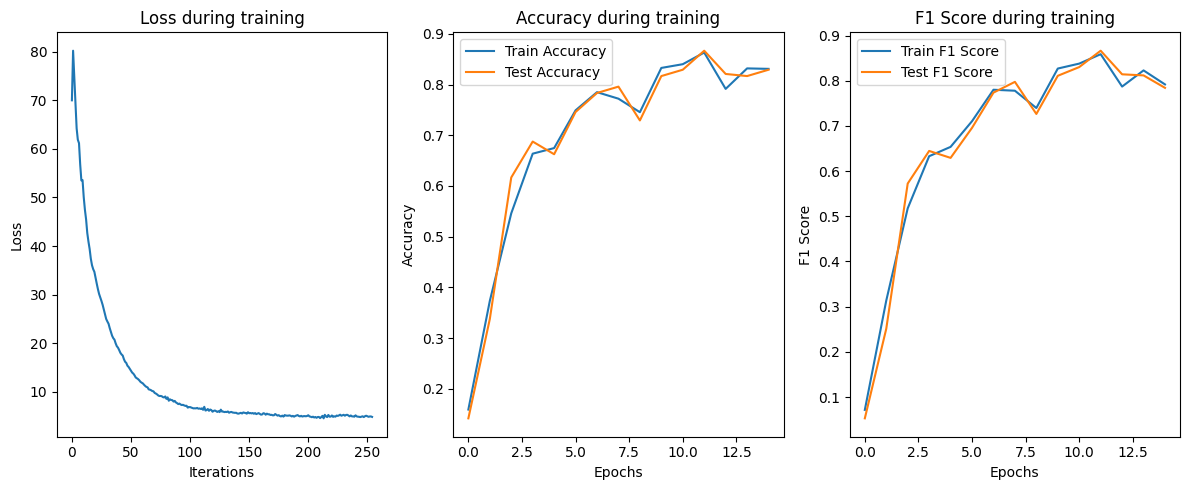

In [ ]:
all_losses = []
train_accuracies = []
test_accuracies = []
train_f1_scores = []
test_f1_scores = []

# Funkcja do obliczania metryk na zbiorze
def compute_metrics(model, data_loader, device):
    model.eval()  # Ustawienie modelu w tryb ewaluacji
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return accuracy, f1

# Trening modelu
l1_lambda = 0.001  # Siła regularyzacji L1

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Dodanie kary L1
        l1_reg = torch.tensor(0., requires_grad=True).to(device)
        for name, param in model.named_parameters():
            if 'weight' in name:
                l1_reg = l1_reg + torch.norm(param, 1)

        loss = loss + l1_lambda * l1_reg # dodanie kary L1 do funkcji straty

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        if (i + 1) % 2 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}')

        # Zbieranie strat
        all_losses.append(loss.item())

    # Obliczanie metryk na treningowym zbiorze
    train_accuracy, train_f1 = compute_metrics(model, train_loader, device)
    train_accuracies.append(train_accuracy)
    train_f1_scores.append(train_f1)

    # Obliczanie metryk na testowym zbiorze
    test_accuracy, test_f1 = compute_metrics(model, test_loader, device)
    test_accuracies.append(test_accuracy)
    test_f1_scores.append(test_f1)

    print(f'Epoch [{epoch+1}/{num_epochs}] Training Accuracy: {train_accuracy:.4f}, F1 Score: {train_f1:.4f}')
    print(f'Epoch [{epoch+1}/{num_epochs}] Test Accuracy: {test_accuracy:.4f}, F1 Score: {test_f1:.4f}')

# Rysowanie wykresów
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(all_losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Loss during training')

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy during training')
plt.legend()

# F1 Score
plt.subplot(1, 3, 3)
plt.plot(train_f1_scores, label='Train F1 Score')
plt.plot(test_f1_scores, label='Test F1 Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('F1 Score during training')
plt.legend()


plt.tight_layout()
plt.show()


In [ ]:
# Zapis modelu po treningu
torch.save(model.state_dict(), 'model1_whole_pic.pth')
print('Model saved successfully.')

Model saved successfully.


Ten model uznałam za dobrze wytrenowany który może posłużyć do dalszych analiz. Kolejnym celem było sprawdzenie, jakie klasy model najczęściej przewiduje źle:

<ipython-input-169-2a602d674df6>:39: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("model1_whole_pic.pth", map_location=device)) # Załaduj s

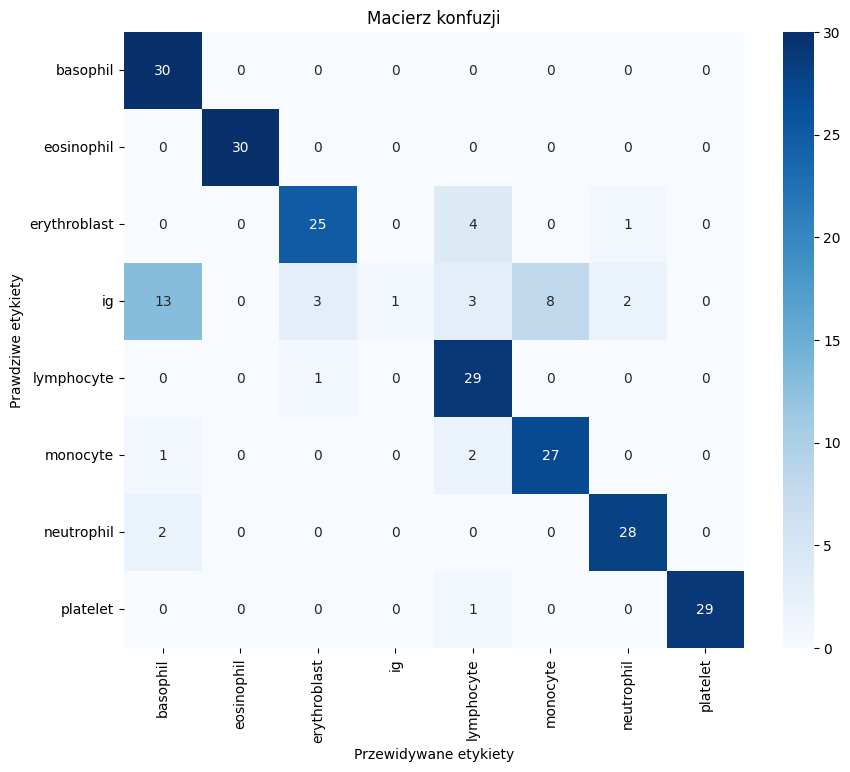

              precision    recall  f1-score   support

    basophil       0.65      1.00      0.79        30
  eosinophil       1.00      1.00      1.00        30
erythroblast       0.86      0.83      0.85        30
          ig       1.00      0.03      0.06        30
  lymphocyte       0.74      0.97      0.84        30
    monocyte       0.77      0.90      0.83        30
  neutrophil       0.90      0.93      0.92        30
    platelet       1.00      0.97      0.98        30

    accuracy                           0.83       240
   macro avg       0.87      0.83      0.78       240
weighted avg       0.87      0.83      0.78       240



In [ ]:
# Jakie klasy najczęściej źle przewiduje model ?
def evaluate_model(model, data_loader, device):
    """
    Funkcja do ewaluacji modelu i zwrócenia prawdziwych i przewidywanych etykiet.
    """
    model.eval()
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            true_labels.extend(labels.cpu().numpy())
            pred_labels.extend(preds.cpu().numpy())

    return true_labels, pred_labels

def plot_confusion_matrix(true_labels, pred_labels, class_names):
    """
    Tworzenie i wizualizacja macierzy konfuzji.
    """
    cm = confusion_matrix(true_labels, pred_labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Przewidywane etykiety")
    plt.ylabel("Prawdziwe etykiety")
    plt.title("Macierz konfuzji")
    plt.show()

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ConvNet(num_classes=10)
model.load_state_dict(torch.load("model1_whole_pic.pth", map_location=device))
model.to(device)
model.eval()

true_labels, pred_labels = evaluate_model(model, test_loader, device)
class_names = ["basophil", "eosinophil", "erythroblast", "ig", "lymphocyte", "monocyte", "neutrophil", "platelet"]

plot_confusion_matrix(true_labels, pred_labels, class_names)
print(classification_report(true_labels, pred_labels, target_names=class_names))



# Interpretacja wyników klasyfikacji za pomocą 1 modelu:

## Miary oceny:
- **Precision (Precyzja)**:  
  Odsetek próbek poprawnie przewidzianych jako należące do danej klasy w stosunku do wszystkich próbek przewidzianych jako należące do tej klasy.  
  Wysoka precyzja oznacza mało fałszywych pozytywów.

- **Recall (Czułość)**:  
  Odsetek próbek poprawnie przewidzianych jako należące do danej klasy w stosunku do wszystkich faktycznych próbek tej klasy.  
  Wysoka czułość oznacza mało fałszywych negatywów.

- **F1-Score**:  
  Średnia harmoniczna precyzji i czułości, zapewniająca równowagę między nimi.

- **Support (Wspieranie)**:  
  Liczba faktycznych próbek każdej klasy w zbiorze danych.

## Ogólna dokładność:
- **Accuracy (Dokładność)**:  
  Całkowity odsetek poprawnie sklasyfikowanych próbek.  
  Tutaj dokładność wynosi **0.83 (83%)**.

## Analiza wyników:

- Klasa **„ig”** okazała się być najgorzej przewidywana przez model.

- Ogólnie, model osiąga dobre statystyki i nadaje się do późniejszych analiz.


----

<h2> Model 2 - wytrenowanych na "celu": <br>

Przygotowanie danych:

Konieczne było pobranie na nowo datasetu ponieważ tutaj potrzebne były dane z maskami:

In [ ]:
# Definicje folderów
base_dir = kagglehub.dataset_download("mahdihabibi/segmented-peripheral-blood-cells-using-opencv")
image_dir = os.path.join(base_dir, "original_images/original_images")
mask_dir = os.path.join(base_dir, "binary_masks/binary_masks")

# Funkcja do zbierania plików z obrazami i maskami z podfolderów
def get_image_mask_paths(image_dir, mask_dir):
    image_paths = []
    mask_paths = []

    # Przechodzimy przez wszystkie podfoldery w katalogu z obrazami
    for subdir, _, files in os.walk(image_dir):
        for file in files:
            if file.endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(subdir, file))

    # Przechodzimy przez wszystkie podfoldery w katalogu z maskami
    for subdir, _, files in os.walk(mask_dir):
        for file in files:
            if file.endswith(('.jpg', '.jpeg', '.png')):
                mask_paths.append(os.path.join(subdir, file))

    return image_paths, mask_paths

image_paths, mask_paths = get_image_mask_paths(image_dir, mask_dir)

# Podziel dane na zbiór treningowy (70%), walidacyjny (15%) i testowy (15%)
image_train, image_temp, mask_train, mask_temp = train_test_split(image_paths, mask_paths, test_size=0.3, random_state=42)
image_val, image_test, mask_val, mask_test = train_test_split(image_temp, mask_temp, test_size=0.5, random_state=42)
print(f"Treningowy: {len(image_train)} obrazów")
print(f"Walidacyjny: {len(image_val)} obrazów")
print(f"Testowy: {len(image_test)} obrazów")

100%|██████████| 29.8M/29.8M [00:00<00:00, 129MB/s]

Extracting files...


Treningowy: 1092 obrazów
Walidacyjny: 234 obrazów
Testowy: 234 obrazów


Wyodrębnienie celu - tło zdjęcia na szaro i zapis do folderu:

In [ ]:
import cv2
def apply_mask(image_path, mask_path, output_path):
    # Wczytanie obrazu i maski
    image = cv2.imread(image_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Odczyt maski w odcieniach szarości

    # Jeśli maska i obraz mają różne rozmiary, dostosuj maskę do rozmiaru obrazu
    if image.shape[:2] != mask.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]))

    # Stworzenie obrazu z szarym tłem
    gray_background = np.full_like(image, (128, 128, 128))  # Szare tło (R=128, G=128, B=128)

    _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    # Stosowanie maski do obrazu: zachowanie tylko obszaru maski, reszta na szaro
    result = np.where(binary_mask[..., None] == 255, image, gray_background)

    # Zapisanie wyniku
    cv2.imwrite(output_path, result)


def create_output_directories(base_output_dir, image_path):
    # Ekstrakcja folderu z obrazu w stosunku do głównego katalogu z obrazami
    relative_path = os.path.relpath(image_path, image_dir)  # Ścieżka względna do obrazu
    output_dir = os.path.join(base_output_dir, os.path.dirname(relative_path))  # Zachowuje strukturę podfolderów
    os.makedirs(output_dir, exist_ok=True)
    return os.path.join(output_dir, os.path.basename(image_path))  # Pełna ścieżka zapisu


os.makedirs(os.path.join("cropped_output", "train"), exist_ok=True)
os.makedirs(os.path.join("cropped_output", "val"), exist_ok=True)
os.makedirs(os.path.join("cropped_output", "test"), exist_ok=True)

# Przetwórz obrazy w zbiorze treningowym
for img_path, mask_path in zip(image_train, mask_train):
    output_path = create_output_directories("cropped_output/train", img_path)
    apply_mask(img_path, mask_path, output_path)

# Przetwórz obrazy w zbiorze walidacyjnym
for img_path, mask_path in zip(image_val, mask_val):
    output_path = create_output_directories("cropped_output/val", img_path)
    apply_mask(img_path, mask_path, output_path)

# Przetwórz obrazy w zbiorze testowym
for img_path, mask_path in zip(image_test, mask_test):
    output_path = create_output_directories("cropped_output/test", img_path)
    apply_mask(img_path, mask_path, output_path)


I znowu konieczne ujednolicenie rozmiaru każdego zdjęcia :)

In [ ]:
# Resize każdego obrazu:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Funkcja do interpolacji obrazu
def resize_image(image_path, new_width, new_height, filter_size=(3, 3), padding=0, stride=1):
    # Wczytanie obrazu
    img = Image.open(image_path)
    img_array = np.array(img)

    # Wymiary oryginalnego obrazu
    H, W = img_array.shape

    # Rozszerzenie obrazu (padding)
    padded_image = np.pad(img_array, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)

    # Nowe wymiary obrazu po konwolucji
    output_height = (H - filter_size[0] + 2 * padding) // stride + 1
    output_width = (W - filter_size[1] + 2 * padding) // stride + 1

    # Nowy obraz (wyjściowy)
    resized_image = np.zeros((new_height, new_width))

    # Przesuwanie filtru po obrazie i wykonywanie interpolacji
    for i in range(new_height):
        for j in range(new_width):
            x_start = int(j * (W / new_width))
            y_start = int(i * (H / new_height))
            x_end = x_start + filter_size[1]
            y_end = y_start + filter_size[0]

            region = padded_image[y_start:y_end, x_start:x_end]
            resized_image[i, j] = np.mean(region)

    return resized_image

    from PIL import Image
import os

# Funkcja do zmiany rozmiaru obrazu
def resize_image_pillow(image_path, new_width, new_height, save_path):
    try:
        # Wczytanie obrazu
        img = Image.open(image_path)

        # Zmiana rozmiaru z interpolacją
        resized_img = img.resize((new_width, new_height), Image.LANCZOS)  # Image.ANTIALIAS zapewnia wysoką jakość interpolacji

        # Zapis przeskalowanego obrazu
        resized_img.save(save_path)

    except Exception as e:
        print(f"Błąd podczas przetwarzania {image_path}: {e}")


base_dir = "./cropped_output/"
output_dir = "./resized_data_cropped/"
os.makedirs(output_dir, exist_ok=True)

splits = ['train', 'val', 'test']

# Nowe wymiary obrazów
new_width = 360
new_height = 363

# Przetwarzanie wszystkich obrazów
for split in splits:
    input_dir = os.path.join(base_dir, split)
    output_split_dir = os.path.join(output_dir, split)
    os.makedirs(output_split_dir, exist_ok=True)

    for class_name in os.listdir(input_dir):
        class_input_dir = os.path.join(input_dir, class_name)
        class_output_dir = os.path.join(output_split_dir, class_name)
        os.makedirs(class_output_dir, exist_ok=True)

        for img_name in os.listdir(class_input_dir):
            img_path = os.path.join(class_input_dir, img_name)
            output_path = os.path.join(class_output_dir, img_name)

            try:
                resize_image_pillow(img_path, new_width, new_height, output_path)
            except Exception as e:
                print(f"Błąd podczas przetwarzania {img_path}: {e}")

print("Wszystkie obrazy zostały przetworzone.")

Wszystkie obrazy zostały przetworzone.


Utworzenie DataLoadera dla danych treningowych i testowych. Tutaj zostawiam już jedynie ostateczny model który okazał się być najlepszy spośród wszystkich - bałam się że ten notebook będzie zbyt zabałaganiony i nic Pan z niego nie zrozumie :(

Tutaj najlepszym okazało się rozmiar batch_size = 128

In [ ]:
# Na cropped:
base_dir = "./resized_data_cropped/train"
batch_size = 128

transform = transforms.Compose([
    # Augmentacja
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomHorizontalFlip(),  # Losowe odbicie w poziomie
    transforms.RandomVerticalFlip(),   # Losowe odbicie w pionie
    transforms.RandomAffine(30, shear=10, scale=(0.8, 1.2)),  # Losowe przesunięcie, obrót, skalowanie
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])

dataset = ImageFolder(root=base_dir, transform=transform)
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


base_dir = "./resized_data_cropped/test"

transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])


dataset = ImageFolder(root=base_dir, transform=transform)
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ConvNet, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.fc1 = nn.Linear(128 * 45 * 45, 256)
        self.fc2 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)

        out = out.view(out.size(0), -1)

        out = self.dropout(out)
        out = self.fc1(out)
        out = nn.ReLU()(out)
        out = self.fc2(out)

        return out

In [ ]:
total_step = len(train_loader)
#Parametry do trenowania
num_epochs = 20
learning_rate = 0.0001
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = ConvNet(num_classes).to(device)
#Wybieramy funckje kosztu i optymalizator - dodanie L2 - WEIGHT DECAY
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)

Epoch [1/20], Step [2/9], Loss: 72.1002
Epoch [1/20], Step [4/9], Loss: 66.9137
Epoch [1/20], Step [6/9], Loss: 61.5687
Epoch [1/20], Step [8/9], Loss: 54.0345
Epoch [1/20] Training Accuracy: 0.2967, F1 Score: 0.2215
Epoch [1/20] Test Accuracy: 0.2479, F1 Score: 0.1795
Epoch [2/20], Step [2/9], Loss: 45.0147
Epoch [2/20], Step [4/9], Loss: 40.6629
Epoch [2/20], Step [6/9], Loss: 36.8999
Epoch [2/20], Step [8/9], Loss: 33.7406
Epoch [2/20] Training Accuracy: 0.4212, F1 Score: 0.3801
Epoch [2/20] Test Accuracy: 0.4786, F1 Score: 0.4078
Epoch [3/20], Step [2/9], Loss: 29.6932
Epoch [3/20], Step [4/9], Loss: 28.0751
Epoch [3/20], Step [6/9], Loss: 26.2580
Epoch [3/20], Step [8/9], Loss: 24.5649
Epoch [3/20] Training Accuracy: 0.5385, F1 Score: 0.4977
Epoch [3/20] Test Accuracy: 0.5385, F1 Score: 0.4995
Epoch [4/20], Step [2/9], Loss: 22.2821
Epoch [4/20], Step [4/9], Loss: 20.6512
Epoch [4/20], Step [6/9], Loss: 19.3170
Epoch [4/20], Step [8/9], Loss: 18.1936
Epoch [4/20] Training Accuracy

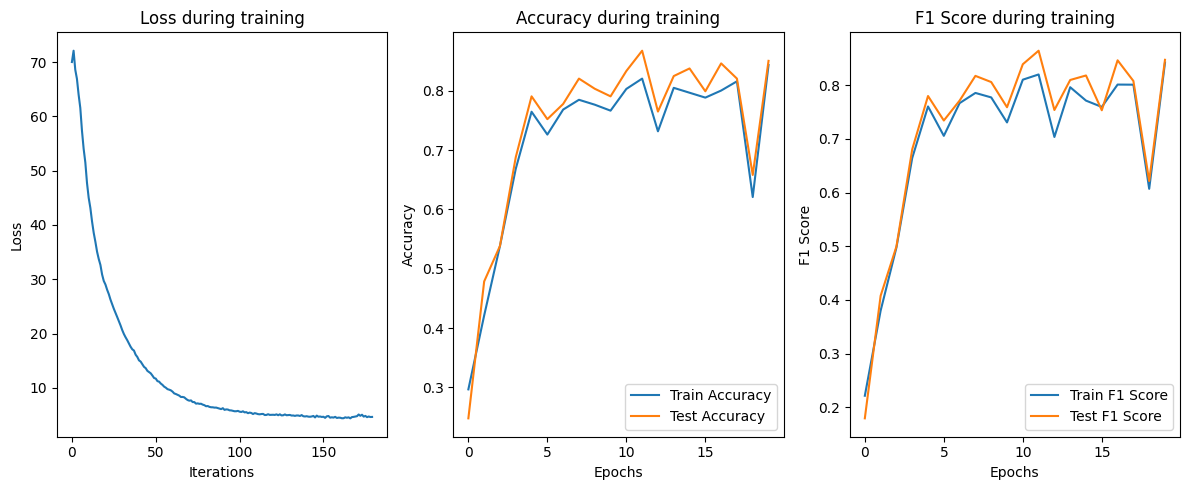

In [ ]:
# Inicjalizacja list do zbierania metryk i strat
all_losses = []
train_accuracies = []
test_accuracies = []
train_f1_scores = []
test_f1_scores = []

# Funkcja do obliczania metryk na zbiorze
def compute_metrics(model, data_loader, device):
    model.eval()  # Ustawienie modelu w tryb ewaluacji
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return accuracy, f1

# Trening modelu
l1_lambda = 0.001  # Siła regularyzacji L1

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Krok forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Dodanie kary L1
        l1_reg = torch.tensor(0., requires_grad=True).to(device) # upewnienie się, że tensor jest na GPU
        for name, param in model.named_parameters():
            if 'weight' in name:
                l1_reg = l1_reg + torch.norm(param, 1)

        loss = loss + l1_lambda * l1_reg # dodanie kary L1 do funkcji straty

        # Krok backward i optymalizacja
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

        if (i + 1) % 2 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}')

        # Zbieranie strat
        all_losses.append(loss.item())

    # Obliczanie metryk na treningowym zbiorze
    train_accuracy, train_f1 = compute_metrics(model, train_loader, device)
    train_accuracies.append(train_accuracy)
    train_f1_scores.append(train_f1)

    # Obliczanie metryk na testowym zbiorze
    test_accuracy, test_f1 = compute_metrics(model, test_loader, device)
    test_accuracies.append(test_accuracy)
    test_f1_scores.append(test_f1)

    print(f'Epoch [{epoch+1}/{num_epochs}] Training Accuracy: {train_accuracy:.4f}, F1 Score: {train_f1:.4f}')
    print(f'Epoch [{epoch+1}/{num_epochs}] Test Accuracy: {test_accuracy:.4f}, F1 Score: {test_f1:.4f}')

# Rysowanie wykresów
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 3, 1)
plt.plot(all_losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Loss during training')

# Accuracy
plt.subplot(1, 3, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy during training')
plt.legend()

# F1 Score
plt.subplot(1, 3, 3)
plt.plot(train_f1_scores, label='Train F1 Score')
plt.plot(test_f1_scores, label='Test F1 Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.title('F1 Score during training')
plt.legend()


plt.tight_layout()
plt.show()


In [ ]:
# Zapis modelu po treningu
torch.save(model.state_dict(), 'model1_cropped_photos.pth')
print('Model saved successfully.')

Model saved successfully.


<ipython-input-12-1de84d97c11a>:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("Model2_cropped_photos.pth", map_location=device)) # Załad

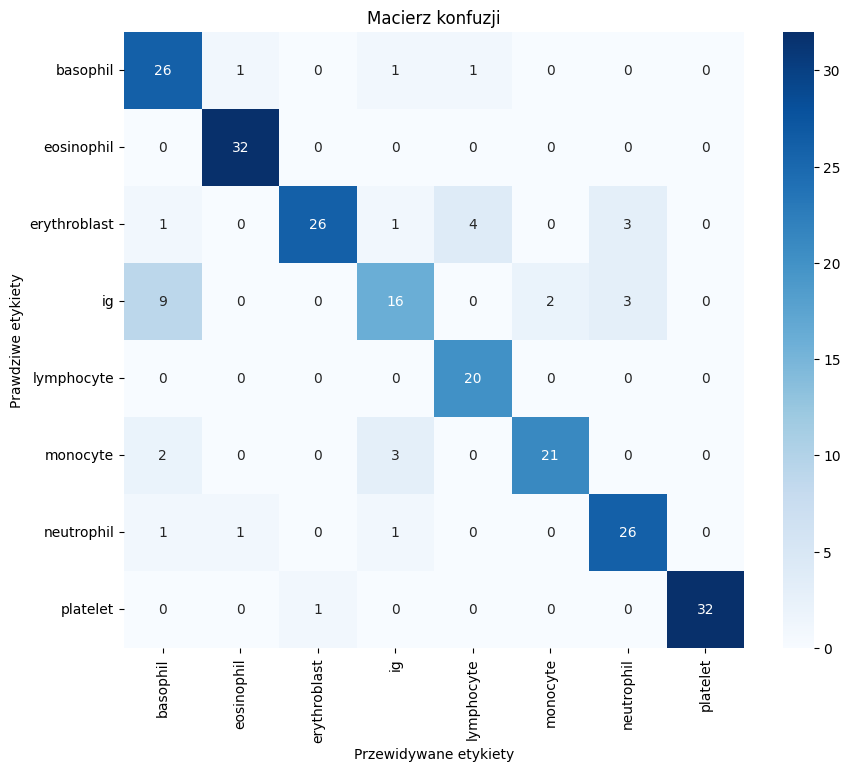

              precision    recall  f1-score   support

    basophil       0.67      0.90      0.76        29
  eosinophil       0.94      1.00      0.97        32
erythroblast       0.96      0.74      0.84        35
          ig       0.73      0.53      0.62        30
  lymphocyte       0.80      1.00      0.89        20
    monocyte       0.91      0.81      0.86        26
  neutrophil       0.81      0.90      0.85        29
    platelet       1.00      0.97      0.98        33

    accuracy                           0.85       234
   macro avg       0.85      0.86      0.85       234
weighted avg       0.86      0.85      0.85       234



In [ ]:
# Jakie klasy najczęściej źle przewiduje model ?
def evaluate_model(model, data_loader, device):
    """
    Funkcja do ewaluacji modelu i zwrócenia prawdziwych i przewidywanych etykiet.
    """
    model.eval()
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for batch in data_loader:
            images, labels = batch[0], batch[1]  # Przyjmujemy, że obrazy to batch[0], a etykiety to batch[1]
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            true_labels.extend(labels.cpu().numpy())
            pred_labels.extend(preds.cpu().numpy())

    return true_labels, pred_labels


def plot_confusion_matrix(true_labels, pred_labels, class_names):
    """
    Tworzenie i wizualizacja macierzy konfuzji.
    """
    cm = confusion_matrix(true_labels, pred_labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Przewidywane etykiety")
    plt.ylabel("Prawdziwe etykiety")
    plt.title("Macierz konfuzji")
    plt.show()

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Załaduj model, definiując architekturę
model = ConvNet(num_classes=10)  # Utwórz instancję modelu ConvNet
model.load_state_dict(torch.load("Model2_cropped_photos.pth", map_location=device)) # Załaduj stan modelu, przenosząc go na GPU
model.to(device)  # Upewnij się, że model jest na GPU
model.eval()  # Ustaw model w tryb ewaluacji

true_labels, pred_labels = evaluate_model(model, test_loader, device)
class_names = ["basophil", "eosinophil", "erythroblast", "ig", "lymphocyte", "monocyte", "neutrophil", "platelet"]

plot_confusion_matrix(true_labels, pred_labels, class_names)
print(classification_report(true_labels, pred_labels, target_names=class_names))



Ten model okazał się lepiej przewidywać klasę ig z którą był problem przy pierwszym modelu. Również statystyki jak precision czy recall lub dokładność są lepsze w tym modelu.

-----

<h2> 3. Model 3 - wytrenowany w oparciu o cechy morfologiczne oraz zdjęcia mikroskpowe na wyciętym "celu"

In [ ]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops
from torch.utils.data import Dataset, DataLoader

In [ ]:
# --- Ekstrakcja cech morfologicznych ---
def extract_morphological_features(image, bounding_box):
    x_min, y_min, x_max, y_max = bounding_box
    cropped_cell = image[y_min:y_max, x_min:x_max]

    _, binary_cell = cv2.threshold(cropped_cell, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(binary_cell, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        contour = contours[0]

        area = cv2.contourArea(contour)
        perimeter = cv2.arcLength(contour, True)
        _, _, w, h = cv2.boundingRect(contour)


        glcm = graycomatrix(cropped_cell, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]

        return [
            area, perimeter, contrast, homogeneity
        ]
    return [0] * 4

1. Cechy morfologiczne (geometryczne): <br>
- Pole powierzchni (area):
Obliczane za pomocą funkcji cv2.contourArea(contour); określa liczbę pikseli w obrębie konturu obiektu.
- Obwód (perimeter):
Mierzony jako suma długości wszystkich krawędzi konturu za pomocą.

2. Cechy teksturalne (GLCM - macierz współwystępowania poziomów szarości):
- Kontrast (contrast):
Miara różnic intensywności między sąsiednimi pikselami. Obliczana z macierzy współwystępowania (graycomatrix) za pomocą funkcji graycoprops(glcm, 'contrast').
- Jednorodność (homogeneity):
Miara, jak bardzo wartości sąsiadujących pikseli są podobne. Również obliczana z GLCM za pomocą graycoprops(glcm, 'homogeneity').


Czyli:


- Pole powierzchni (area) – wielkość obiektu.
- Obwód (perimeter) – długość konturu.
- Kontrast (contrast) – różnice intensywności w sąsiedztwie.
- Jednorodność (homogeneity) – podobieństwo intensywności w sąsiedztwie.


---

To będzie później wykorzystywane przy stworzeniu loadera który będzie zawierał zarówno zdjęcia jak i cechy morfologiczne dla każdego zdjęcia:

In [ ]:
from PIL import Image
from torch.utils.data import Dataset

class CellDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        # Przejście po folderach i plikach
        for label, class_name in enumerate(os.listdir(image_dir)):
            class_path = os.path.join(image_dir, class_name)
            if os.path.isdir(class_path):
                for img_file in os.listdir(class_path):
                    if img_file.endswith(".jpg"):  # Tylko obrazy JPG
                        self.image_paths.append(os.path.join(class_path, img_file))
                        self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # Wczytaj obraz w kolorze
        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Konwersja na RGB

        # Wymiary obrazu
        h, w = image.shape[:2]
        bounding_box = [0, 0, w, h]  # Przyjmijmy cały obraz jako bounding box

        # Ekstrakcja cech morfologicznych
        morph_features = extract_morphological_features(image[:, :, 0], bounding_box)
        morph_features = np.array(morph_features, dtype=np.float32)

        # Konwersja obrazu do formatu PIL.Image
        image = Image.fromarray(image)

        # Zastosowanie transformacji do obrazu
        if self.transform:
            image = self.transform(image)

        return image, morph_features, label  # Zwrócenie obrazu, cech morfologicznych i etykiety


Stworzenie DataLoadera:

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
# Ustawienia
base_dir = "./resized_data_cropped/train"
batch_size = 64

# Definicja transformacji
transform = transforms.Compose([
    # Augmentacja
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomHorizontalFlip(),  # Losowe odbicie w poziomie
    transforms.RandomVerticalFlip(),   # Losowe odbicie w pionie
    transforms.RandomAffine(30, shear=10, scale=(0.8, 1.2)),  # Losowe przesunięcie, obrót, skalowanie
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])

# Używamy CellDataset - do dodania cech morfologicznych
dataset = CellDataset(image_dir=base_dir, transform=transform)

# Przygotowanie DataLoader
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


base_dir = "./resized_data_cropped/test"

transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])
# Używamy CellDataset zamiast ImageFolder
dataset = CellDataset(image_dir=base_dir, transform=transform)

# Przygotowanie DataLoader
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


Ostateczny wytrenowany model:

Tutaj proste modele nie sprawdzały się, konieczne było zwiększenie warstw konwolucyjnych oraz dodanie większej ilości filtrów:

In [ ]:
import torch
import torch.nn as nn

class HybridModel(nn.Module):
    def __init__(self, num_classes=10):
        super(HybridModel, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),  # Dodana warstwa
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Ścieżka morfologii - ze zwiększonym rozmiarem i Batch Normalization
        self.morph_fc = nn.Sequential(
            nn.Linear(4, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        # Połączenie obu ścieżek - ze zwiększonym rozmiarem i Batch Normalization
        self.fc_combined = nn.Sequential(
            nn.Linear(128 * 45 * 45 + 64, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, image, morph_features):
        # Przetwarzanie obrazu
        image_features = self.cnn(image)
        image_features = image_features.view(image_features.size(0), -1)

        # Przetwarzanie cech morfologicznych
        morph_features = self.morph_fc(morph_features)

        # Połączenie cech
        combined_features = torch.cat((image_features, morph_features), dim=1)
        out = self.fc_combined(combined_features)

        return out

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
# Ustawienia
base_dir = "./resized_data_cropped/train"
batch_size = 128

# Definicja transformacji
transform = transforms.Compose([
    # Augmentacja
    transforms.RandomRotation(30),  # Obrót obrazu o losowy kąt
    transforms.RandomHorizontalFlip(),  # Losowe odbicie w poziomie
    transforms.RandomVerticalFlip(),   # Losowe odbicie w pionie
    transforms.RandomAffine(30, shear=10, scale=(0.8, 1.2)),  # Losowe przesunięcie, obrót, skalowanie
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])

# Używamy CellDataset zamiast ImageFolder
dataset = CellDataset(image_dir=base_dir, transform=transform)

# Przygotowanie DataLoader
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


base_dir = "./resized_data_cropped/test"

transform = transforms.Compose([
    transforms.ToTensor(),  # Konwersja do tensora
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalizacja
])
# Używamy CellDataset zamiast ImageFolder
dataset = CellDataset(image_dir=base_dir, transform=transform)

# Przygotowanie DataLoader
test_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


Funkcja do trenowania modelu:

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import matplotlib.pyplot as plt

def train_hybrid_model(model, train_loader, test_loader, criterion, optimizer, device, num_epochs, l1_lambda=0.001):

    # Inicjalizacja list do zbierania metryk i strat
    all_losses = []
    train_accuracies = []
    test_accuracies = []
    train_f1_scores = []
    test_f1_scores = []

    # Funkcja do obliczania metryk na zbiorze
    def compute_metrics(model, data_loader, device):
        model.eval()  # Ustawienie modelu w tryb ewaluacji
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for images, morph_features, labels in data_loader:
                # Przenieś dane na urządzenie
                images = images.to(device)
                morph_features = morph_features.to(device)
                labels = labels.to(device)

                # Przewidywanie
                outputs = model(images, morph_features)
                _, preds = torch.max(outputs, 1)

                # Zbieranie wyników
                all_preds.append(preds.cpu().numpy())
                all_labels.append(labels.cpu().numpy())

        all_preds = np.concatenate(all_preds)
        all_labels = np.concatenate(all_labels)

        accuracy = accuracy_score(all_labels, all_preds)
        f1 = f1_score(all_labels, all_preds, average='weighted')

        return accuracy, f1

    # Trening modelu
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, (images, morph_features, labels) in enumerate(train_loader):
            images = images.to(device)
            morph_features = morph_features.to(device)
            labels = labels.to(device)

            # Krok forward
            outputs = model(images, morph_features)
            loss = criterion(outputs, labels)

            # Dodanie kary L1
            l1_reg = torch.tensor(0., requires_grad=True).to(device)
            for name, param in model.named_parameters():
                if 'weight' in name:
                    l1_reg = l1_reg + torch.norm(param, 1)

            loss = loss + l1_lambda * l1_reg  # Dodanie kary L1 do funkcji straty

            # Krok backward i optymalizacja
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            # Drukowanie informacji o treningu
            if (i + 1) % 2 == 0:
                print(f'Epoch [{epoch + 1}/{num_epochs}], Step [{i + 1}/{len(train_loader)}], Loss: {loss.item():.4f}')

            # Zbieranie strat
            all_losses.append(loss.item())

        # Obliczanie metryk na treningowym zbiorze
        train_accuracy, train_f1 = compute_metrics(model, train_loader, device)
        train_accuracies.append(train_accuracy)
        train_f1_scores.append(train_f1)

        # Obliczanie metryk na testowym zbiorze
        test_accuracy, test_f1 = compute_metrics(model, test_loader, device)
        test_accuracies.append(test_accuracy)
        test_f1_scores.append(test_f1)

        print(f'Epoch [{epoch + 1}/{num_epochs}] Training Accuracy: {train_accuracy:.4f}, F1 Score: {train_f1:.4f}')
        print(f'Epoch [{epoch + 1}/{num_epochs}] Test Accuracy: {test_accuracy:.4f}, F1 Score: {test_f1:.4f}')

    # Rysowanie wykresów
    plt.figure(figsize=(12, 5))

    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(all_losses, label='Loss')
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.title('Loss during training')

    # Accuracy
    plt.subplot(1, 3, 2)
    plt.plot(train_accuracies, label='Train Accuracy')
    plt.plot(test_accuracies, label='Test Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy during training')
    plt.legend()

    # F1 Score
    plt.subplot(1, 3, 3)
    plt.plot(train_f1_scores, label='Train F1 Score')
    plt.plot(test_f1_scores, label='Test F1 Score')
    plt.xlabel('Epochs')
    plt.ylabel('F1 Score')
    plt.title('F1 Score during training')
    plt.legend()

    plt.tight_layout()
    plt.show()

Epoch [1/10], Step [2/9], Loss: 2.3997
Epoch [1/10], Step [4/9], Loss: 1.6291
Epoch [1/10], Step [6/9], Loss: 1.4120
Epoch [1/10], Step [8/9], Loss: 1.3555
Epoch [1/10] Training Accuracy: 0.1172, F1 Score: 0.0246
Epoch [1/10] Test Accuracy: 0.1410, F1 Score: 0.0349
Epoch [2/10], Step [2/9], Loss: 1.2463
Epoch [2/10], Step [4/9], Loss: 1.0855
Epoch [2/10], Step [6/9], Loss: 1.0356
Epoch [2/10], Step [8/9], Loss: 1.0170
Epoch [2/10] Training Accuracy: 0.2216, F1 Score: 0.1466
Epoch [2/10] Test Accuracy: 0.2564, F1 Score: 0.1713
Epoch [3/10], Step [2/9], Loss: 0.8729
Epoch [3/10], Step [4/9], Loss: 0.8457
Epoch [3/10], Step [6/9], Loss: 0.9350
Epoch [3/10], Step [8/9], Loss: 0.7785
Epoch [3/10] Training Accuracy: 0.3690, F1 Score: 0.2953
Epoch [3/10] Test Accuracy: 0.4017, F1 Score: 0.3000
Epoch [4/10], Step [2/9], Loss: 0.6814
Epoch [4/10], Step [4/9], Loss: 0.6940
Epoch [4/10], Step [6/9], Loss: 0.7054
Epoch [4/10], Step [8/9], Loss: 0.6636
Epoch [4/10] Training Accuracy: 0.5156, F1 Sco

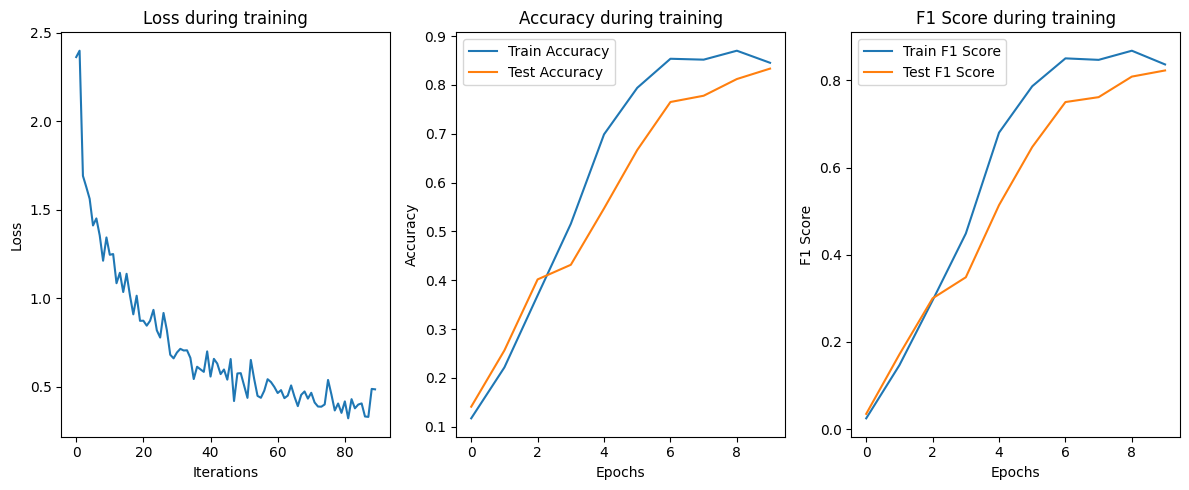

In [ ]:
total_step = len(train_loader)
#Parametry do trenowania
num_epochs = 10
learning_rate = 0.0001
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = HybridModel(num_classes).to(device)
#Wybieramy funckje kosztu i optymalizator - dodanie L2 - WEIGHT DECAY
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)
train_hybrid_model(model, train_loader, test_loader, criterion, optimizer, device, num_epochs)

In [ ]:
total_step = len(train_loader)
#Parametry do trenowania
num_epochs = 10
learning_rate = 0.0001
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu') #uzyj karty graficznej (GPU) do obliczen jeśli jest dostępna
num_classes = 10
model = HybridModel(num_classes).to(device)
#Wybieramy funckje kosztu i optymalizator - dodanie L2 - WEIGHT DECAY
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-5)

Epoch [1/10], Step [2/9], Loss: 14.0420
Epoch [1/10], Step [4/9], Loss: 13.1009
Epoch [1/10], Step [6/9], Loss: 12.2214
Epoch [1/10], Step [8/9], Loss: 11.5087
Epoch [1/10] Training Accuracy: 0.3388, F1 Score: 0.2308
Epoch [1/10] Test Accuracy: 0.3504, F1 Score: 0.2331
Epoch [2/10], Step [2/9], Loss: 10.6397
Epoch [2/10], Step [4/9], Loss: 10.1958
Epoch [2/10], Step [6/9], Loss: 9.7562
Epoch [2/10], Step [8/9], Loss: 9.3518
Epoch [2/10] Training Accuracy: 0.5229, F1 Score: 0.4611
Epoch [2/10] Test Accuracy: 0.5085, F1 Score: 0.4368
Epoch [3/10], Step [2/9], Loss: 8.8253
Epoch [3/10], Step [4/9], Loss: 8.7831
Epoch [3/10], Step [6/9], Loss: 8.3987
Epoch [3/10], Step [8/9], Loss: 8.2420
Epoch [3/10] Training Accuracy: 0.7179, F1 Score: 0.6821
Epoch [3/10] Test Accuracy: 0.7521, F1 Score: 0.7033
Epoch [4/10], Step [2/9], Loss: 8.2021
Epoch [4/10], Step [4/9], Loss: 8.1279
Epoch [4/10], Step [6/9], Loss: 7.8102
Epoch [4/10], Step [8/9], Loss: 7.8239
Epoch [4/10] Training Accuracy: 0.7995, 

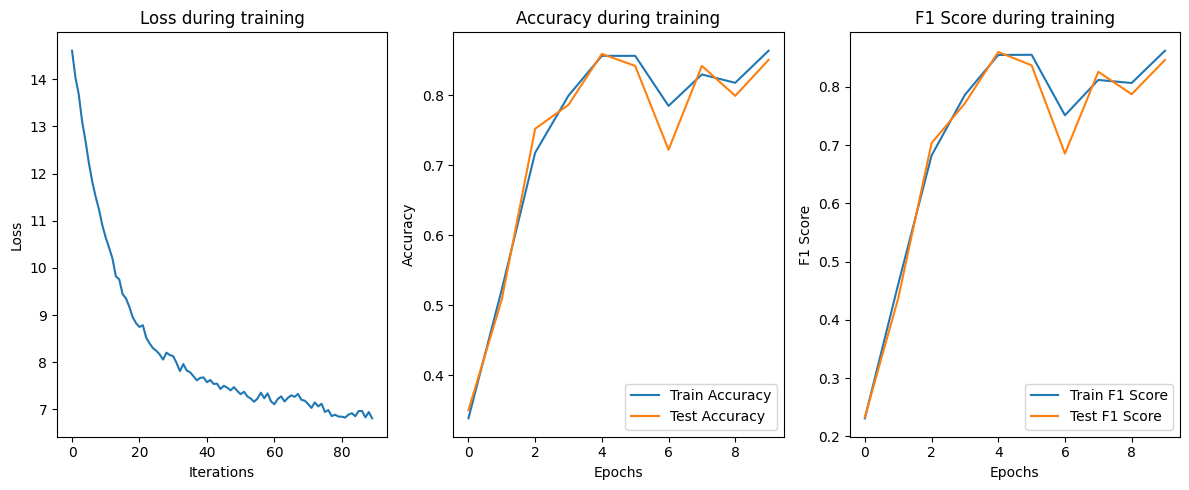

In [ ]:
train_hybrid_model(model, train_loader, test_loader, criterion, optimizer, device, num_epochs)

Te wyniki uznałam za dobre i zapisałam model.

In [ ]:
# Zapis modelu po treningu
torch.save(model.state_dict(), 'model_hybrid.pth')
print('Model saved successfully.')

Model saved successfully.


Ewaluacja modelu:

Sprawdzenie jakie klasy model przewiduje najgorzej:

<ipython-input-24-3afd25e60d8a>:43: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("Model_3_cell_metrics.pth", map_location=device))  # Zmień

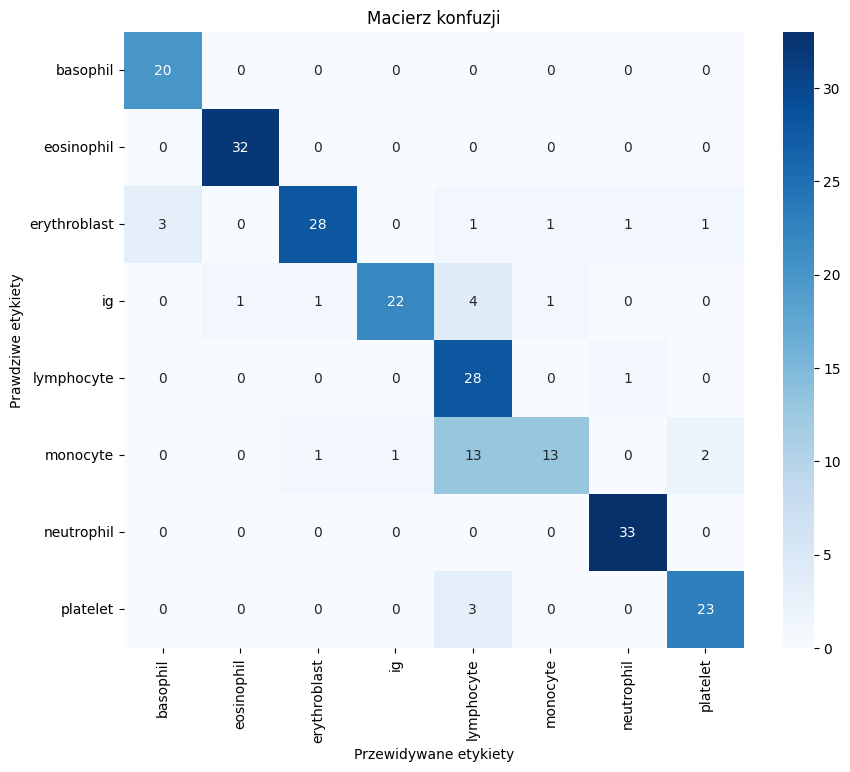

              precision    recall  f1-score   support

    basophil       0.87      1.00      0.93        20
  eosinophil       0.97      1.00      0.98        32
erythroblast       0.93      0.80      0.86        35
          ig       0.96      0.76      0.85        29
  lymphocyte       0.57      0.97      0.72        29
    monocyte       0.87      0.43      0.58        30
  neutrophil       0.94      1.00      0.97        33
    platelet       0.88      0.88      0.88        26

    accuracy                           0.85       234
   macro avg       0.87      0.86      0.85       234
weighted avg       0.88      0.85      0.85       234



In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_hybrid_model(model, data_loader, device):
    """
    Ewaluacja modelu HybridModel i zwrócenie prawdziwych oraz przewidywanych etykiet.
    """
    model.eval()
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for batch in data_loader:
            images, morph_features, labels = batch  # Zakładamy, że data_loader zwraca (images, morph_features, labels)
            images, morph_features, labels = images.to(device), morph_features.to(device), labels.to(device)

            outputs = model(images, morph_features)
            _, preds = torch.max(outputs, 1)

            true_labels.extend(labels.cpu().numpy())
            pred_labels.extend(preds.cpu().numpy())

    return true_labels, pred_labels

def plot_confusion_matrix(true_labels, pred_labels, class_names):
    """
    Tworzenie i wizualizacja macierzy konfuzji.
    """
    cm = confusion_matrix(true_labels, pred_labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Przewidywane etykiety")
    plt.ylabel("Prawdziwe etykiety")
    plt.title("Macierz konfuzji")
    plt.show()

# Załaduj model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = HybridModel(num_classes=10)
model.load_state_dict(torch.load("Model_3_cell_metrics.pth", map_location=device))
model.to(device)

# Ewaluacja modelu
true_labels, pred_labels = evaluate_hybrid_model(model, test_loader, device)

# Klasy danych (przykładowe nazwy, dostosuj do swoich danych)
class_names = ["basophil", "eosinophil", "erythroblast", "ig", "lymphocyte", "monocyte", "neutrophil", "platelet"]

# Wizualizacja wyników
plot_confusion_matrix(true_labels, pred_labels, class_names)
print(classification_report(true_labels, pred_labels, target_names=class_names))


Trzeci model nie okazał się być lepszy w klasyfikacji - jednak może być to spowodowane źle dobraną architekturą modelu. Jednak spośród wszystkich wytrenowanych modeli to właśnie ta architektura dawała najlepsze wyniki.

Może posiadanie więcej czasu i głębsze zastanowienie się jakie dodatkowe cechy morfologiczne można wyciągnąć żeby ulepszyć model pozwoliłoby na zdobywanie większych wyników.

Ku zaskoczeniu tutaj model nie miał problemów z przewidywaniem klasy ig. Może cechy morfologiczne pozwoliły na sprawne rozróżnienie.

Wygląda natomiast jakby cechy morfologiczne mogły zaburzyć rozpoznawanie klasy monocytów.